# Tutorial GNN: Datos Reales (MoleculeNet) y Mecanismos de Atención con Aristas
Este notebook integra datos químicos reales de **MoleculeNet (MUTAG)** e implementa capas de atención convolucional **GATv2Conv** que consideran atributos de aristas.
<br>
Cada molécula es un grafo representada por un un punto de datos, dentro de la cual, tanto los nodos (átomos) como las aristas (enlaces) contienen varios atributos.

In [ ]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 30.8 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo activo: {device}")

Dispositivo activo: cpu


## 1. Carga de Compuestos Químicos Reales de MoleculeNet

In [ ]:
from torch_geometric.datasets import TUDataset

# Utilisation de TUDataset à la place de MoleculeNet pour charger MUTAG
dataset = TUDataset(root='data/MUTAG', name='MUTAG')
print(f"Total moléculas en el dataset: {len(dataset)}")
print(f"Características por átomo (nodo): {dataset.num_features}")

torch.manual_seed(42)
dataset = dataset.shuffle()
train_dataset = dataset[:int(len(dataset) * 0.8)]
test_dataset = dataset[int(len(dataset) * 0.8):]

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Total moléculas en el dataset: 188
Características por átomo (nodo): 7


Veamos el conjunto de datos

In [ ]:
molecula_0 = dataset[0]
print(molecula_0)

Data(edge_index=[2, 44], x=[21, 7], edge_attr=[44, 4], y=[1])



# Estructura de una Entrada en MUTAG


|Atributo del Objeto Data |	Dimensión / Formato	|Significado en Química	| Explicación Técnica |
|---|---|---|---|
|x (Node Features) |	[Num_Átomos, 7]|	Los Átomos de la molécula.	| Matriz con la codificación One-Hot del elemento químico de cada átomo (C, N, O, F, I, Cl, Br).|
|edge_index (Conectividad)|	[2, Num_Enlaces]|	Los Enlaces químicos.|	Matriz dispersa de adyacencia que conecta los índices de los átomos (de dónde a dónde va el enlace).|
|edge_attr (Edge Features)	|[Num_Enlaces, 4]	|El Tipo de enlace químico.	Matriz con la codificación | One-Hot del tipo de enlace (simple, doble, triple o aromático).|
|y (Label)	|[1]|	Mutagenicidad del compuesto.|	Clasificación binaria: 1 si es mutagénico (tóxico/causa mutaciones), 0 si no lo es.|


In [ ]:
molecula_0["x"]

tensor([[1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0.]])

In [ ]:
molecula_0["edge_index"]

tensor([[ 0,  0,  1,  1,  2,  2,  2,  3,  3,  4,  4,  4,  5,  5,  6,  6,  6,  7,
          8,  9,  9,  9, 10, 10, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 15, 15,
         15, 16, 17, 18, 18, 18, 19, 20],
        [ 1,  5,  0,  2,  1,  3,  9,  2,  4,  3,  5,  6,  0,  4,  4,  7,  8,  6,
          6,  2, 10, 14,  9, 11, 10, 12, 11, 13, 18, 12, 14, 15,  9, 13, 13, 16,
         17, 15, 15, 12, 19, 20, 18, 18]])

In [ ]:
molecula_0["edge_attr"]

tensor([[1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 1., 0., 0.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0.,

In [ ]:
molecula_0["y"]

tensor([1])

# Visualización de una molécula

In [ ]:
from torch_geometric.utils import to_networkx

ejemplo_molécula = dataset[34]

# Convertir el objeto Data de PyG a un grafo de NetworkX
G_pyg = to_networkx(ejemplo_molécula, to_undirected=True)

print(f"Nodos cargados: {G_pyg.number_of_nodes()}")
print(f"Enlaces cargados: {G_pyg.number_of_edges()}")
print(f"Etiqueta de mutagenicidad (Clase): {ejemplo_molécula.y.item()}")

Nodos cargados: 19
Enlaces cargados: 21
Etiqueta de mutagenicidad (Clase): 1


In [ ]:
G_pyg.nodes(data=True)

NodeDataView({0: {}, 1: {}, 2: {}, 3: {}, 4: {}, 5: {}, 6: {}, 7: {}, 8: {}, 9: {}, 10: {}, 11: {}, 12: {}, 13: {}, 14: {}, 15: {}, 16: {}, 17: {}, 18: {}, 19: {}, 20: {}})

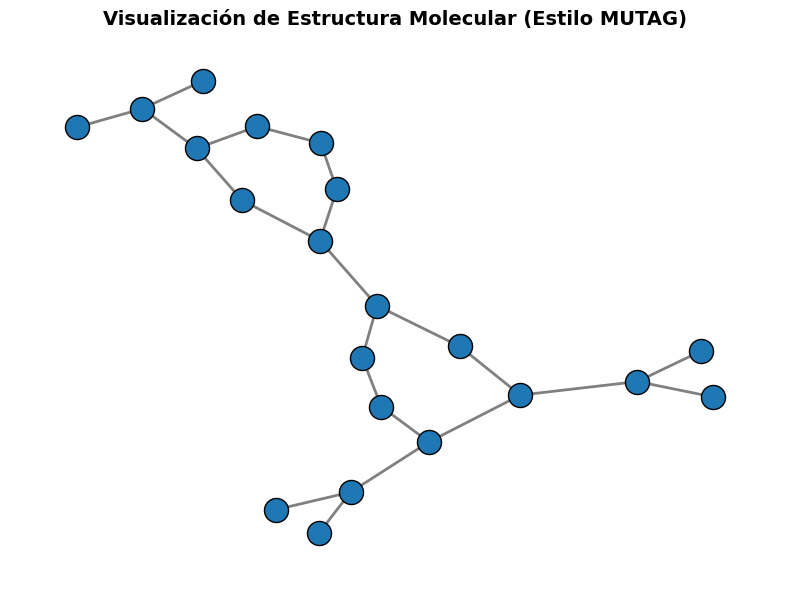

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Usamos el algoritmo spring_layout para distribuir los átomos armoniosamente
G=G_pyg.copy()
pos = nx.spring_layout(G, seed=42)

# Extraer propiedades para el dibujo
# colores_nodos = [G.nodes[n]["color"] for n in G.nodes]
# tamaños_nodos = [G.nodes[n]["tamaño"] for n in G.nodes]
# etiquetas_nodos = {n: G.nodes[n]["elemento"] for n in G.nodes}

# 3. Renderizar la visualización con Matplotlib
plt.figure(figsize=(8, 6))
plt.title(
    "Visualización de Estructura Molecular (Estilo MUTAG)",
    fontsize=14,
    fontweight="bold",
)

# Dibujar nodos
nx.draw_networkx_nodes(
    G, pos , edgecolors="black"
)

# Dibujar enlaces
nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")

# Dibujar etiquetas de los elementos químicos (C, N, O)
#nx.draw_networkx_labels(
#    G, pos, labels=etiquetas_nodos, font_size=12, font_weight="bold"
#)

plt.axis("off")  # Ocultar los ejes coordenados
plt.tight_layout()
plt.show()


# Tarea:
Mejora de la visualizacion teniendo en cuenta los atributos
* Colorear y etiquetar nodos
* Marcar los enlaces según su tipo





En el caso de moléculas, claramente, el tamaño es variable. Por lo cual es necesario concentrar la información de todos los nodos en un solo nodo (que representa a la molecula completa) esto se hace con una capa de tipo
dropout.

Notamos también que las aristas contienen más de un atributo, por lo cual la librería *NNConv* no puede ser utilizada. En su lugar, **GATv2Conv** admite atributos multidimensionales así como coeficientes dinámicos en la interacción entre átomos vecinos.

## 2. Red Neuronal con Atención en Aristas (Edge Attention)

In [ ]:
class MolecularEdgeAttentionGNN(nn.Module):
    def __init__(self, num_node_features, num_edge_features, hidden_dim, num_classes, heads=2):
        super(MolecularEdgeAttentionGNN, self).__init__()

        self.conv1 = GATv2Conv(
            in_channels=num_node_features,
            out_channels=hidden_dim,
            heads=heads,
            edge_dim=num_edge_features,
            concat=True
        )

        self.conv2 = GATv2Conv(
            in_channels=hidden_dim * heads,
            out_channels=hidden_dim,
            heads=1,
            edge_dim=num_edge_features,
            concat=False
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x, edge_index, edge_attr, batch):
        x = x.float()
        if edge_attr is not None:
            edge_attr = edge_attr.float()

        x = self.conv1(x, edge_index, edge_attr=edge_attr)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)

        x = self.conv2(x, edge_index, edge_attr=edge_attr)
        x = F.relu(x)

        x_graph = global_mean_pool(x, batch)
        return self.classifier(x_graph)

sample_batch = next(iter(train_loader))
num_edge_feats = sample_batch.edge_attr.shape[1] if sample_batch.edge_attr is not None else 4

model = MolecularEdgeAttentionGNN(
            num_node_features=dataset.num_features,
            num_edge_features=num_edge_feats,
            hidden_dim=32,
            num_classes=dataset.num_classes,
            heads=2
        ).to(device)
print(model)

MolecularEdgeAttentionGNN(
  (conv1): GATv2Conv(7, 32, heads=2)
  (conv2): GATv2Conv(64, 32, heads=1)
  (classifier): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=2, bias=True)
  )
)


## 3. Entrenamiento y Validación

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

def train():
    model.train()
    total_loss = 0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.edge_attr, data.batch)
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_loader.dataset)

def test(loader):
    model.eval()
    correct = 0
    for data in loader:
        data = data.to(device)
        with torch.no_grad():
            out = model(data.x, data.edge_index, data.edge_attr, data.batch)
            pred = out.argmax(dim=-1)
            correct += int((pred == data.y).sum())
    return correct / len(loader.dataset)

for epoch in range(1, 11):
    loss = train()
    train_acc = test(train_loader)
    test_acc = test(test_loader)
    print(f"Época: {epoch:02d} | Pérdida: {loss:.4f} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

Época: 01 | Pérdida: 0.6209 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 02 | Pérdida: 0.6213 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 03 | Pérdida: 0.6214 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 04 | Pérdida: 0.6138 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 05 | Pérdida: 0.6157 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 06 | Pérdida: 0.6098 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 07 | Pérdida: 0.6081 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 08 | Pérdida: 0.5863 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 09 | Pérdida: 0.5739 | Train Acc: 0.6933 | Test Acc: 0.5526
Época: 10 | Pérdida: 0.5459 | Train Acc: 0.7200 | Test Acc: 0.6842


# Observaciones

Las capas convolucionales obtienen canales de nodos cercanos, sin embargo en enlaces aromaticos existe un "enlace tipo anillo" que no se toma en cuenta.

Para que nodos lejanos sean usados tambien en una capa convolucional, se puede por ejemplo usar
**nodos virtuales**

In [ ]:

class VirtualNodeAttentionGNN(nn.Module):
    def __init__(self, num_node_features, num_edge_features, hidden_dim, num_classes, num_layers=2):
        super(VirtualNodeAttentionGNN, self).__init__()

        self.num_layers = num_layers

        # 1. Capas Convolucionales locales (Atención en Aristas)
        self.convs = nn.ModuleList([
            GATv2Conv(num_node_features, hidden_dim, edge_dim=num_edge_features) if i == 0
            else GATv2Conv(hidden_dim, hidden_dim, edge_dim=num_edge_features)
            for i in range(num_layers)
        ])

        # 2. Capas de actualización para el Nodo Virtual (un vector por cada grafo en el batch)
        # Se usa una capa lineal (o MLP) para transformar la memoria global en cada paso
        self.vn_layers = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim) for _ in range(num_layers - 1)
        ])

        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x, edge_index, edge_attr, batch):
        x = x.float()
        if edge_attr is not None:
            edge_attr = edge_attr.float()

        # Inicializamos el estado del Nodo Virtual para cada grafo del lote en ceros
        # batch.max() + 1 nos da el número de grafos en el mini-batch
        num_graphs = batch.max().item() + 1
        vn_embedding = torch.zeros(num_graphs, x.size(-1), device=x.device)

        for i in range(self.num_layers):
            # --- PASO A: Convolución Local Clásica ---
            x = self.convs[i](x, edge_index, edge_attr=edge_attr)

            # --- PASO B: Inyección del Mensaje del Nodo Virtual ---
            # El nodo real 'i' recibe la información global de su respectivo grafo 'batch'
            x = x + vn_embedding[batch]
            x = F.relu(x)

            # --- PASO C: Actualización del Estado del Nodo Virtual ---
            if i < self.num_layers - 1:
                # 1. Agregamos las nuevas características de los nodos reales usando un pooling
                global_info = global_mean_pool(x, batch) # Dimensión: [num_graphs, hidden_dim]

                # 2. El nodo virtual procesa la información agregada y actualiza su memoria
                vn_embedding = vn_embedding + F.relu(self.vn_layers[i](global_info))

        # Readout final de la molécula y clasificación
        graph_representation = global_mean_pool(x, batch)
        return self.classifier(graph_representation)

In [ ]:
model_v = VirtualNodeAttentionGNN(
            num_node_features=dataset.num_features,
            num_edge_features=num_edge_feats,
            hidden_dim=32,
            num_classes=dataset.num_classes,
            num_layers=2
        ).to(device)
print(model_v)

VirtualNodeAttentionGNN(
  (convs): ModuleList(
    (0): GATv2Conv(7, 32, heads=1)
    (1): GATv2Conv(32, 32, heads=1)
  )
  (vn_layers): ModuleList(
    (0): Linear(in_features=32, out_features=32, bias=True)
  )
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)


Entrenamos el modelo modificado

In [ ]:
# 1. Configuración de Dispositivo y Carga de Datos (MUTAG)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Utilizando dispositivo: {device}")



# Mezclar y dividir el dataset (80% Entrenamiento, 20% Prueba)
torch.manual_seed(42)
dataset = dataset.shuffle()
train_dataset = dataset[:150]
test_dataset = dataset[150:]

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# 2. Definición de la Arquitectura con Nodo Virtual (VN)
class VirtualNodeGATv2(nn.Module):
    def __init__(self, num_node_features, num_edge_features, hidden_dim, num_classes):
        super(VirtualNodeGATv2, self).__init__()

        # Convoluciones locales con atención que integran los enlaces (edge_dim)
        self.conv1 = GATv2Conv(num_node_features, hidden_dim, edge_dim=num_edge_features)
        self.conv2 = GATv2Conv(hidden_dim, hidden_dim, edge_dim=num_edge_features)

        # Capa lineal para actualizar la memoria del Nodo Virtual entre capas
        self.vn_layer = nn.Linear(hidden_dim, hidden_dim)

        # Clasificador MLP final
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x, edge_index, edge_attr, batch):
        x = x.float()
        if edge_attr is not None:
            edge_attr = edge_attr.float()

        # --- SOLUCIÓN: El Nodo Virtual se inicializa con el tamaño oculto (64) ---
        num_graphs = batch.max().item() + 1
        hidden_dim = self.conv1.out_channels # Obtenemos el 64 dinámicamente
        vn_embedding = torch.zeros(num_graphs, hidden_dim, device=x.device)

        # --- CAPA 1 ---
        x = self.conv1(x, edge_index, edge_attr=edge_attr) # Salida: [n, 64]
        x = x + vn_embedding[batch]  # Ahora sí: [n, 64] + [n, 64] = [n, 64]
        x = torch.relu(x)

        # Actualización del Nodo Virtual: Los nodos reales le envían su mensaje
        global_info = global_mean_pool(x, batch)
        vn_embedding = vn_embedding + torch.relu(self.vn_layer(global_info))

        # --- CAPA 2 ---
        x = self.conv2(x, edge_index, edge_attr=edge_attr) # Salida: [n, 64]
        x = x + vn_embedding[batch]  # [n, 64] + [n, 64]
        x = torch.relu(x)

        # Readout Global Final (Pooling)
        graph_representation = global_mean_pool(x, batch)
        return self.classifier(graph_representation)

# 3. Inicialización del Modelo, Optimizador y Criterio de Pérdida
model = VirtualNodeGATv2(
    num_node_features=dataset.num_node_features,
    num_edge_features=dataset.num_edge_features,
    hidden_dim=64,
    num_classes=dataset.num_classes
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

# 4. Funciones de Entrenamiento y Evaluación
def train():
    model.train()
    total_loss = 0
    correct = 0
    for data in train_loader:
        data = data.to(device)
        optimizer.zero_grad()

        # Predicción y cálculo de error
        out = model(data.x, data.edge_index, data.edge_attr, data.batch)
        loss = criterion(out, data.y.squeeze().long())
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * data.num_graphs
        pred = out.argmax(dim=-1)
        correct += int((pred == data.y.squeeze()).sum())

    return total_loss / len(train_dataset), correct / len(train_dataset)

def test(loader):
    model.eval()
    correct = 0
    for data in loader:
        data = data.to(device)
        with torch.no_grad():
            out = model(data.x, data.edge_index, data.edge_attr, data.batch)
        pred = out.argmax(dim=-1)
        correct += int((pred == data.y.squeeze()).sum())
    return correct / len(loader.dataset)

# 5. Ejecución del Bucle de Entrenamiento (Training Loop)
print("\n--- Iniciando Entrenamiento con Nodo Virtual + GATv2 ---")
for epoch in range(1, 81):
    train_loss, train_acc = train()
    test_acc = test(test_loader)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Época {epoch:03d} | Pérdida: {train_loss:.4f} | Train Acc: {train_acc*100:.1f}% | Test Acc: {test_acc*100:.1f}%")
print("---------------------------------------------------------")

Utilizando dispositivo: cpu

--- Iniciando Entrenamiento con Nodo Virtual + GATv2 ---
Época 001 | Pérdida: 0.6710 | Train Acc: 59.3% | Test Acc: 68.4%
Época 010 | Pérdida: 0.5252 | Train Acc: 75.3% | Test Acc: 71.1%
Época 020 | Pérdida: 0.4902 | Train Acc: 72.7% | Test Acc: 73.7%
Época 030 | Pérdida: 0.4927 | Train Acc: 75.3% | Test Acc: 73.7%
Época 040 | Pérdida: 0.4799 | Train Acc: 76.0% | Test Acc: 76.3%
Época 050 | Pérdida: 0.4673 | Train Acc: 76.7% | Test Acc: 76.3%
Época 060 | Pérdida: 0.4443 | Train Acc: 77.3% | Test Acc: 76.3%
Época 070 | Pérdida: 0.4248 | Train Acc: 76.0% | Test Acc: 78.9%
Época 080 | Pérdida: 0.4288 | Train Acc: 80.0% | Test Acc: 81.6%
---------------------------------------------------------


--- Entrenando GATv2 + Nodo Virtual Dinámico ---
Época 001 | Loss: 0.4200 | Train Acc: 80.7% | Test Acc: 81.6%
Época 010 | Loss: 0.4316 | Train Acc: 78.7% | Test Acc: 76.3%
Época 020 | Loss: 0.4106 | Train Acc: 79.3% | Test Acc: 81.6%
Época 030 | Loss: 0.4118 | Train Acc: 80.7% | Test Acc: 78.9%
Época 040 | Loss: 0.4189 | Train Acc: 80.7% | Test Acc: 81.6%
Época 050 | Loss: 0.4010 | Train Acc: 79.3% | Test Acc: 78.9%
Época 060 | Loss: 0.3989 | Train Acc: 79.3% | Test Acc: 81.6%
Época 070 | Loss: 0.3995 | Train Acc: 80.0% | Test Acc: 81.6%
Época 080 | Loss: 0.4015 | Train Acc: 80.7% | Test Acc: 81.6%


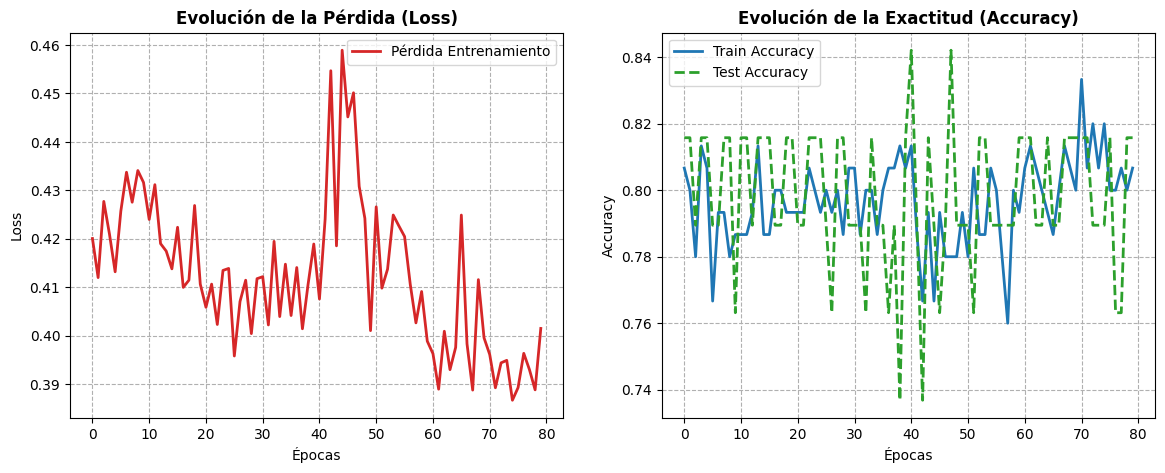


--- MATRIZ DE CONFUSIÓN (Conjunto de Prueba) ---
               Predicho: NO    Predicho: SÍ
Real: NO (0)      [ VN:  6 ]       [ FP:  6 ]
Real: SÍ (1)      [ FN:  1 ]       [ VP: 25 ]
------------------------------------------------


In [ ]:
# 5. Bucle de Entrenamiento
# Historiales para graficar
history = {'train_loss': [], 'train_acc': [], 'test_acc': []}

print("--- Entrenando GATv2 + Nodo Virtual Dinámico ---")
for epoch in range(1, 81):
    loss, train_acc = train()
    test_acc = test(test_loader)

    history['train_loss'].append(loss)
    history['train_acc'].append(train_acc)
    history['test_acc'].append(test_acc)

    if epoch == 1 or epoch % 10 == 0:
        print(f"Época {epoch:03d} | Loss: {loss:.4f} | Train Acc: {train_acc*100:.1f}% | Test Acc: {test_acc*100:.1f}%")

# 6. Generación de Gráficos con Matplotlib
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida
ax1.plot(history['train_loss'], label='Pérdida Entrenamiento', color='#d62728', lw=2)
ax1.set_title('Evolución de la Pérdida (Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--')
ax1.legend()

# Gráfico de Precisión
ax2.plot(history['train_acc'], label='Train Accuracy', color='#1f77b4', lw=2)
ax2.plot(history['test_acc'], label='Test Accuracy', color='#2ca02c', lw=2, linestyle='--')
ax2.set_title('Evolución de la Exactitud (Accuracy)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Accuracy')
ax2.grid(True, linestyle='--')
ax2.legend()

plt.show()

# 7. Cálculo de la Matriz de Confusión Final
model.eval()
all_preds, all_targets = [], []

for data in test_loader:
    data = data.to(device)
    with torch.no_grad():
        preds = model(data.x, data.edge_index, data.edge_attr, data.batch).argmax(dim=-1)
    all_preds.extend(preds.cpu().numpy())
    all_targets.extend(data.y.squeeze().cpu().numpy())

# Calcular valores de la matriz para clasificación binaria
tp = sum((t == 1 and p == 1) for t, p in zip(all_targets, all_preds))
fp = sum((t == 0 and p == 1) for t, p in zip(all_targets, all_preds))
fn = sum((t == 1 and p == 0) for t, p in zip(all_targets, all_preds))
tn = sum((t == 0 and p == 0) for t, p in zip(all_targets, all_preds))

print("\n--- MATRIZ DE CONFUSIÓN (Conjunto de Prueba) ---")
print(f"               Predicho: NO    Predicho: SÍ")
print(f"Real: NO (0)      [ VN: {tn:2d} ]       [ FP: {fp:2d} ]")
print(f"Real: SÍ (1)      [ FN: {fn:2d} ]       [ VP: {tp:2d} ]")
print("------------------------------------------------")